In [1]:
import seaborn as sns
from sklearn.datasets import make_blobs

In [21]:
X,y=make_blobs(
    n_samples=1000,
    n_features=2,
    centers=4,
    random_state=42
)

<Axes: >

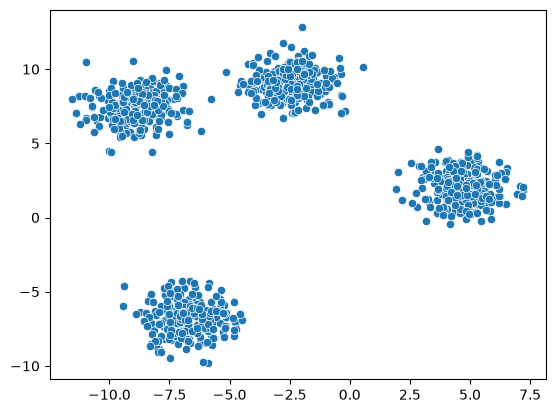

In [8]:
# Visulatize the data
sns.scatterplot(x=X[:,0],y=X[:,1])

In [9]:
# K Means Clustering
from sklearn.cluster import KMeans

In [12]:
K=4
kmeans=KMeans(
    n_clusters=K,
    random_state=42
)

In [23]:
labels=kmeans.fit_predict(X)
#label = cluster number

<Axes: >

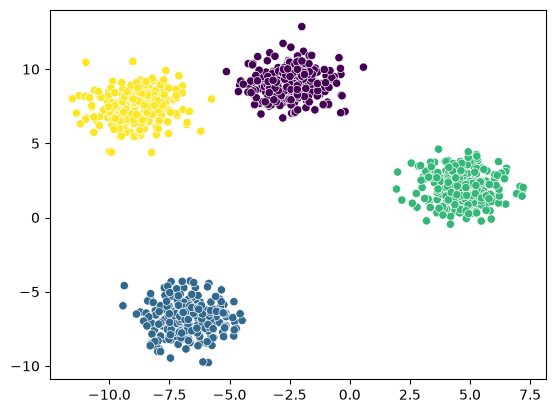

In [24]:
sns.scatterplot(x=X[:,0],y=X[:,1],c=labels)

In [25]:
labels

array([3, 1, 1, 2, 2, 1, 2, 1, 1, 2, 2, 3, 0, 1, 1, 1, 0, 0, 0, 2, 2, 3,
       3, 3, 2, 2, 0, 0, 1, 2, 1, 1, 1, 0, 0, 3, 1, 2, 3, 3, 2, 1, 2, 3,
       2, 3, 0, 2, 3, 2, 1, 0, 2, 3, 0, 3, 0, 0, 0, 1, 1, 0, 1, 3, 2, 0,
       1, 1, 2, 0, 3, 0, 2, 1, 2, 3, 2, 0, 2, 0, 1, 0, 0, 0, 2, 3, 1, 1,
       0, 0, 0, 0, 2, 2, 3, 2, 3, 0, 2, 1, 2, 3, 3, 0, 3, 2, 2, 0, 1, 0,
       3, 1, 2, 2, 2, 2, 1, 3, 1, 2, 0, 1, 3, 2, 3, 1, 2, 3, 1, 2, 0, 1,
       2, 3, 2, 3, 0, 1, 2, 2, 0, 0, 3, 3, 3, 2, 2, 0, 0, 0, 0, 3, 1, 1,
       0, 2, 0, 2, 2, 3, 1, 0, 2, 1, 0, 0, 2, 1, 3, 1, 2, 0, 0, 2, 0, 3,
       1, 3, 1, 3, 2, 2, 0, 1, 0, 1, 2, 3, 0, 1, 2, 0, 2, 2, 0, 3, 1, 1,
       1, 3, 0, 1, 2, 0, 2, 2, 1, 0, 2, 1, 1, 3, 1, 1, 2, 0, 1, 0, 3, 2,
       3, 3, 1, 0, 3, 0, 2, 1, 1, 0, 0, 1, 0, 3, 1, 1, 3, 1, 1, 2, 1, 3,
       1, 2, 3, 0, 2, 0, 2, 2, 2, 2, 3, 2, 2, 1, 0, 1, 1, 2, 2, 2, 3, 2,
       3, 3, 1, 2, 0, 3, 2, 0, 2, 1, 0, 3, 2, 3, 1, 2, 3, 1, 3, 2, 1, 0,
       0, 1, 0, 3, 3, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1,

### Choose our k Value - elbow; silhouette score

In [26]:
# Elbow Method: Find the optimal number of clusters
wcss = []  # Store Within-Cluster Sum of Squares for each k

for k in range(1, 21):  # Test cluster numbers from 1 to 20
    kmeans = KMeans(n_clusters=k)  # Create KMeans model with k clusters
    kmeans.fit_predict(X)  # Fit the model and assign each sample to a cluster
    wcss.append(kmeans.inertia_)  # Store WCSS (sum of squared distances from cluster centers)

<Axes: >

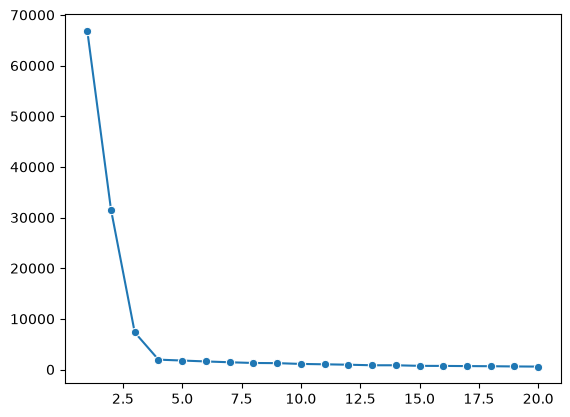

In [27]:
sns.lineplot(x=range(1,21),y=wcss,marker="o")

In [30]:
!pip install kneed

In [33]:
from kneed import KneeLocator

In [35]:
knee=KneeLocator(range(1,21),wcss,curve="convex",direction="decreasing")

In [36]:
print("optimal k= ",knee.elbow)

optimal k=  4


# Silhouette Score

In [39]:
from sklearn.metrics import silhouette_score

In [46]:
# Silhouette Method: Evaluate clustering quality
ss = []  # Store silhouette scores for each k

for k in range(2, 21):  # Test cluster numbers from 2 to 20
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)  # Create KMeans model
    labels = kmeans.fit_predict(X)  # Fit the model and get cluster labels
    score = silhouette_score(X, labels)  # Calculate silhouette score
    ss.append(score)  # Store the silhouette score

<Axes: >

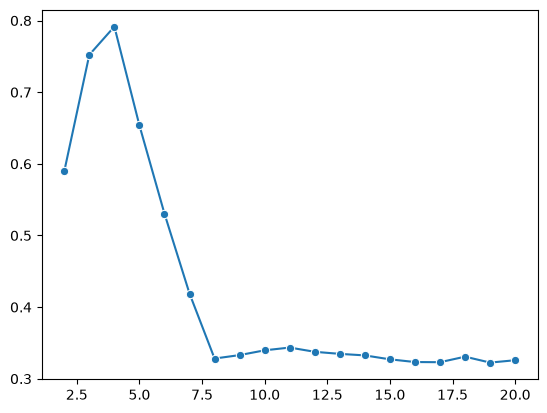

In [49]:
# plot- k & ss
sns.lineplot(x=range(2,21),y=ss,marker='o')